In [2]:
import pandas as pd
import json

# Load program enrollment data
df = pd.read_csv("ProgramTypeCountbyWrittenLanguage.csv")

# Load NYC ZIP code boundaries
with open("nyc-zip-code-tabulation-areas-polygons.geojson", "r") as f:
    nyc_geojson = json.load(f)

# Extract valid NYC ZIP codes
nyc_zip_codes = {
    str(feature["properties"]["postalCode"]).zfill(5)
    for feature in nyc_geojson["features"]
}

# Clean ZIP codes in enrollment data
df["Zip_Code"] = (
    df["Zip_Code"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

# Filter to NYC ZIP codes
nyc_df = df[df["Zip_Code"].isin(nyc_zip_codes)].copy()

# Check results
print("Original rows:", len(df))
print("NYC rows:", len(nyc_df))
print("Rows removed:", len(df) - len(nyc_df))
print("Unique NYC ZIP codes:", nyc_df["Zip_Code"].nunique())

# Save filtered dataset
nyc_df.to_csv(
    "ProgramTypeCountbyWrittenLanguage_NYC.csv",
    index=False
)

# Preview
display(nyc_df.head())

Original rows: 23853
NYC rows: 6499
Rows removed: 17354
Unique NYC ZIP codes: 222


,Zip_Code,Program_Type,Preferred_Written_Language,Enrollments_Count
5,10001,Medicaid,ARABIC,<50
6,10001,Essential Plan,ARABIC,<50
7,10001,Medicaid,CHINESE,177
8,10001,CHP,CHINESE,<50
9,10001,QHP APTC/CSR,CHINESE,<50


In [8]:

import pandas as pd
import numpy as np

# -----------------------------------------
# 1. LOAD NYC DATA
# -----------------------------------------

# Use your previously filtered NYC ZIP code file
df = pd.read_csv(
    "ProgramTypeCountbyWrittenLanguage_NYC.csv",
    dtype={"Zip_Code": "string"}
)

# Clean column names
df.columns = df.columns.str.strip()

print("Available columns:")
print(df.columns.tolist())

# -----------------------------------------
# 2. CLEAN DATA
# -----------------------------------------

# Standardize ZIP codes
df["Zip_Code"] = (
    df["Zip_Code"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

# Standardize program names
df["Program_Type"] = (
    df["Program_Type"]
    .astype("string")
    .str.strip()
)

# Convert enrollment counts to numeric
df["Enrollments_Count"] = pd.to_numeric(
    df["Enrollments_Count"]
    .astype(str)
    .str.replace(",", "", regex=False),
    errors="coerce"
).fillna(0)

# -----------------------------------------
# 3. DEFINE PROGRAM TYPES
# -----------------------------------------

program_types = [
    "Medicaid",
    "CHP",
    "QHP APTC w/o CSR",
    "QHP Full Pay",
    "Essential Plan"
]

# -----------------------------------------
# 4. COMBINE ROWS BY ZIP CODE
# -----------------------------------------

# Sum counts for each ZIP code and program type
# This also combines repeated program entries
# across different written-language rows.

program_pivot = df.pivot_table(
    index="Zip_Code",
    columns="Program_Type",
    values="Enrollments_Count",
    aggfunc="sum",
    fill_value=0
)

# Ensure all five program columns exist
program_pivot = program_pivot.reindex(
    columns=program_types,
    fill_value=0
)

# -----------------------------------------
# 5. CALCULATE TOTAL ENROLLMENTS
# -----------------------------------------

program_pivot["Total_Enrollments"] = (
    program_pivot[program_types].sum(axis=1)
)

# -----------------------------------------
# 6. CALCULATE PERCENTAGES
# -----------------------------------------

# Percentage = program enrollments /
# total ZIP code enrollments * 100

for program in program_types:

    program_pivot[f"{program} Percentage"] = (
        program_pivot[program]
        / program_pivot["Total_Enrollments"].replace(0, np.nan)
        * 100
    ).fillna(0).round(2)

# -----------------------------------------
# 7. RENAME COUNT COLUMNS
# -----------------------------------------

program_pivot = program_pivot.rename(
    columns={
        program: f"{program} Count"
        for program in program_types
    }
)

# -----------------------------------------
# 8. ARRANGE COUNT AND PERCENTAGE SIDE BY SIDE
# -----------------------------------------

ordered_columns = ["Total_Enrollments"]

for program in program_types:
    ordered_columns.extend([
        f"{program} Count",
        f"{program} Percentage"
    ])

program_pivot = program_pivot[ordered_columns]

# -----------------------------------------
# 9. RESET INDEX
# -----------------------------------------

program_zip_df = (
    program_pivot
    .reset_index()
    .sort_values("Zip_Code")
)

# -----------------------------------------
# 10. VALIDATE PERCENTAGES
# -----------------------------------------

percentage_columns = [
    f"{program} Percentage"
    for program in program_types
]

program_zip_df["Percentage_Total"] = (
    program_zip_df[percentage_columns].sum(axis=1)
)

print(
    "Percentage totals (should be approximately 100 "
    "for ZIP codes with enrollments):"
)

print(
    program_zip_df[
        ["Zip_Code", "Percentage_Total"]
    ].head(10)
)

# Remove validation column from final output
program_zip_df = program_zip_df.drop(
    columns="Percentage_Total"
)

# -----------------------------------------
# 11. SAVE NEW DATASET
# -----------------------------------------

program_zip_df.to_csv(
    "NYC_Program_Enrollment_by_ZIP.csv",
    index=False
)

# -----------------------------------------
# 12. DISPLAY RESULTS
# -----------------------------------------

print("Original number of rows:", len(df))
print("Unique NYC ZIP codes:", len(program_zip_df))

display(program_zip_df.head(300))


Available columns:
['Zip_Code', 'Program_Type', 'Preferred_Written_Language', 'Enrollments_Count']
Percentage totals (should be approximately 100 for ZIP codes with enrollments):
Program_Type Zip_Code  Percentage_Total
0               10001            100.01
1               10002            100.00
2               10003            100.01
3               10004            100.00
4               10005            100.00
5               10006            100.00
6               10007            100.00
7               10009            100.00
8               10010            100.00
9               10011            100.00
Original number of rows: 6499
Unique NYC ZIP codes: 222


Program_Type,Zip_Code,Total_Enrollments,Medicaid Count,Medicaid Percentage,CHP Count,CHP Percentage,QHP APTC w/o CSR Count,QHP APTC w/o CSR Percentage,QHP Full Pay Count,QHP Full Pay Percentage,Essential Plan Count,Essential Plan Percentage
0,10001,6119.0,4711.0,76.99,104.0,1.70,112.0,1.83,313.0,5.12,879.0,14.37
1,10002,31922.0,24466.0,76.64,739.0,2.32,421.0,1.32,413.0,1.29,5883.0,18.43
2,10003,5382.0,3478.0,64.62,102.0,1.90,278.0,5.17,739.0,13.73,785.0,14.59
3,10004,342.0,225.0,65.79,0.0,0.00,0.0,0.00,57.0,16.67,60.0,17.54
4,10005,800.0,524.0,65.50,0.0,0.00,0.0,0.00,116.0,14.50,160.0,20.00
...,...,...,...,...,...,...,...,...,...,...,...,...
217,11691,28610.0,22284.0,77.89,2215.0,7.74,245.0,0.86,114.0,0.40,3752.0,13.11
218,11692,7513.0,6303.0,83.89,251.0,3.34,0.0,0.00,0.0,0.00,959.0,12.76
219,11693,3448.0,2999.0,86.98,86.0,2.49,0.0,0.00,0.0,0.00,363.0,10.53
220,11694,3267.0,2489.0,76.19,157.0,4.81,64.0,1.96,92.0,2.82,465.0,14.23


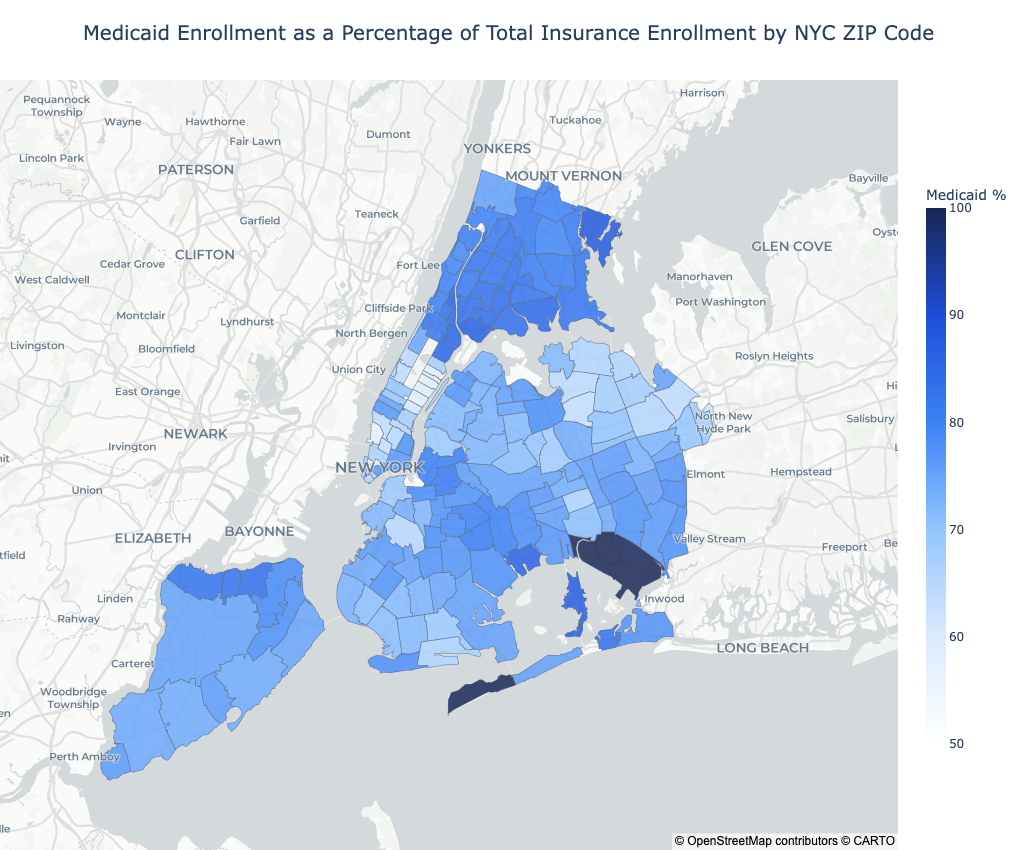

ZIP codes mapped: 181
Minimum Medicaid enrollment percentage: 57.57
Maximum Medicaid enrollment percentage: 100.0


,Zip_Code,Total_Enrollments,Medicaid Count,Medicaid Percentage
221,11697,146.0,146.0,100.000000
210,11430,86.0,86.0,100.000000
105,10464,692.0,609.0,88.005780
95,10454,20463.0,17809.0,87.030250
219,11693,3448.0,2999.0,86.977958
165,11239,4900.0,4228.0,86.285714
36,10039,10932.0,9411.0,86.086718
32,10035,13117.0,11218.0,85.522604
34,10037,6333.0,5400.0,85.267646
26,10029,30500.0,25960.0,85.114754


In [12]:

import pandas as pd
import numpy as np
import json
import plotly.express as px

# -----------------------------------------
# 1. LOAD DATA
# -----------------------------------------

program_zip_df = pd.read_csv(
    "NYC_Program_Enrollment_by_ZIP.csv",
    dtype={"Zip_Code": "string"}
)

with open(
    "nyc-zip-code-tabulation-areas-polygons.geojson",
    "r"
) as f:
    zip_geojson = json.load(f)

program_zip_df.columns = program_zip_df.columns.str.strip()

# -----------------------------------------
# 2. CLEAN ZIP CODES
# -----------------------------------------

program_zip_df["Zip_Code"] = (
    program_zip_df["Zip_Code"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

# -----------------------------------------
# 3. STANDARDIZE GEOJSON ZIP CODES
# -----------------------------------------

for feature in zip_geojson["features"]:
    feature["properties"]["Zip_Code"] = (
        str(feature["properties"]["postalCode"])
        .strip()
        .zfill(5)
    )

# -----------------------------------------
# 4. DEFINE INSURANCE PROGRAMS
# -----------------------------------------

program_types = [
    "Medicaid",
    "CHP",
    "QHP APTC w/o CSR",
    "QHP Full Pay",
    "Essential Plan"
]

count_columns = [
    f"{program} Count"
    for program in program_types
]

# -----------------------------------------
# 5. CLEAN ENROLLMENT COUNTS
# -----------------------------------------

for col in count_columns:
    program_zip_df[col] = pd.to_numeric(
        program_zip_df[col]
        .astype(str)
        .str.replace(",", "", regex=False),
        errors="coerce"
    ).fillna(0)

# -----------------------------------------
# 6. CALCULATE TOTAL ENROLLMENTS
# -----------------------------------------

program_zip_df["Total_Enrollments"] = (
    program_zip_df[count_columns].sum(axis=1)
)

# -----------------------------------------
# 7. CALCULATE ENROLLMENT PERCENTAGES
# -----------------------------------------

for program in program_types:

    program_zip_df[f"{program} Percentage"] = (
        program_zip_df[f"{program} Count"]
        / program_zip_df["Total_Enrollments"].replace(0, np.nan)
        * 100
    )

# -----------------------------------------
# 8. FILTER TO ZIP CODES IN GEOJSON
# -----------------------------------------

mapped_zips = {
    feature["properties"]["Zip_Code"]
    for feature in zip_geojson["features"]
}

map_df = program_zip_df[
    program_zip_df["Zip_Code"].isin(mapped_zips)
].copy()

# Exclude ZIP codes with zero enrollments
map_df = map_df[
    map_df["Total_Enrollments"] > 0
].copy()

# -----------------------------------------
# 9. DEFINE CUSTOM COLOR GRADIENT
# -----------------------------------------

# 50% = white
# 100% = darkest blue

medicaid_colors = [
    [0.00, "#FFFFFF"],  # 50%
    [0.20, "#DBEAFE"],  # 60%
    [0.40, "#93C5FD"],  # 70%
    [0.60, "#3B82F6"],  # 80%
    [0.80, "#1D4ED8"],  # 90%
    [1.00, "#172554"]   # 100%
]

# -----------------------------------------
# 10. DEFINE HOVER DATA
# -----------------------------------------

hover_columns = [
    "Zip_Code",
    "Total_Enrollments",

    "Medicaid Count",
    "Medicaid Percentage",

    "CHP Count",
    "CHP Percentage",

    "QHP APTC w/o CSR Count",
    "QHP APTC w/o CSR Percentage",

    "QHP Full Pay Count",
    "QHP Full Pay Percentage",

    "Essential Plan Count",
    "Essential Plan Percentage"
]

# -----------------------------------------
# 11. CREATE CHOROPLETH MAP
# -----------------------------------------

fig = px.choropleth_map(
    map_df,

    geojson=zip_geojson,

    locations="Zip_Code",

    featureidkey="properties.Zip_Code",

    color="Medicaid Percentage",

    color_continuous_scale=medicaid_colors,

    range_color=(50, 100),

    custom_data=hover_columns,

    map_style="carto-positron",

    center={
        "lat": 40.7128,
        "lon": -73.94
    },

    zoom=9.6,

    opacity=0.85,

    title=(
        "Medicaid Enrollment Percentage "
        "by NYC ZIP Code"
    ),

    height=850
)

# -----------------------------------------
# 12. CUSTOMIZE HOVER INFORMATION
# -----------------------------------------

fig.update_traces(
    hovertemplate=(
        "<b>ZIP Code: %{customdata[0]}</b><br>"
        "<br>"

        "<b>Total Insurance Enrollments:</b> "
        "%{customdata[1]:,.0f}<br>"

        "<br><b>MEDICAID</b><br>"
        "Enrollments: %{customdata[2]:,.0f}<br>"
        "Percentage: %{customdata[3]:.2f}%<br>"

        "<br><b>CHP</b><br>"
        "Enrollments: %{customdata[4]:,.0f}<br>"
        "Percentage: %{customdata[5]:.2f}%<br>"

        "<br><b>QHP APTC w/o CSR</b><br>"
        "Enrollments: %{customdata[6]:,.0f}<br>"
        "Percentage: %{customdata[7]:.2f}%<br>"

        "<br><b>QHP FULL PAY</b><br>"
        "Enrollments: %{customdata[8]:,.0f}<br>"
        "Percentage: %{customdata[9]:.2f}%<br>"

        "<br><b>ESSENTIAL PLAN</b><br>"
        "Enrollments: %{customdata[10]:,.0f}<br>"
        "Percentage: %{customdata[11]:.2f}%"

        "<extra></extra>"
    ),

    marker_line_width=0.6,
    marker_line_color="#64748B"
)

# -----------------------------------------
# 13. CUSTOMIZE COLORBAR
# -----------------------------------------

fig.update_layout(
    coloraxis_colorbar=dict(
        title="Medicaid %",
        ticksuffix="%",
        tickvals=[
            50, 60, 70, 80, 90, 100
        ],
        len=0.75,
        thickness=20
    )
)

# -----------------------------------------
# 14. CUSTOMIZE MAP LAYOUT
# -----------------------------------------

fig.update_layout(
    title=dict(
        text=(
            "Medicaid Enrollment as a Percentage "
            "of Total Insurance Enrollment "
            "by NYC ZIP Code"
        ),
        x=0.5,
        font=dict(size=20)
    ),

    margin=dict(
        l=0,
        r=0,
        t=80,
        b=0
    ),

    height=850,

    paper_bgcolor="white"
)

# -----------------------------------------
# 15. DISPLAY MAP
# -----------------------------------------

fig.show()

# -----------------------------------------
# 16. SAVE INTERACTIVE HTML MAP
# -----------------------------------------

fig.write_html(
    "NYC_Medicaid_Enrollment_Map.html"
)

# -----------------------------------------
# 17. CHECK RESULTS
# -----------------------------------------

print(
    "ZIP codes mapped:",
    map_df["Zip_Code"].nunique()
)

print(
    "Minimum Medicaid enrollment percentage:",
    round(map_df["Medicaid Percentage"].min(), 2)
)

print(
    "Maximum Medicaid enrollment percentage:",
    round(map_df["Medicaid Percentage"].max(), 2)
)

display(
    map_df[
        [
            "Zip_Code",
            "Total_Enrollments",
            "Medicaid Count",
            "Medicaid Percentage"
        ]
    ].sort_values(
        "Medicaid Percentage",
        ascending=False
    ).head(15)
)


In [19]:

import pandas as pd
import numpy as np
import json
import plotly.graph_objects as go

# ==========================================
# 1. LOAD DATA
# ==========================================

insurance = pd.read_csv(
    "NYC_Program_Enrollment_by_ZIP.csv",
    dtype={"Zip_Code": str}
)

deaths = pd.read_csv(
    "CommunityDistrictSingleYearCounts2023.csv"
)

with open(
    "nyc-zip-code-tabulation-areas-polygons.geojson"
) as f:
    zip_geojson = json.load(f)

with open("nyc_districts.geojson") as f:
    cd_geojson = json.load(f)

insurance.columns = insurance.columns.str.strip()
deaths.columns = deaths.columns.str.strip()

# ==========================================
# 2. PREPARE INSURANCE DATA
# ==========================================

insurance["Zip_Code"] = (
    insurance["Zip_Code"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

programs = [
    "Medicaid",
    "CHP",
    "QHP APTC w/o CSR",
    "QHP Full Pay",
    "Essential Plan"
]

count_cols = [f"{p} Count" for p in programs]

for col in count_cols:
    insurance[col] = pd.to_numeric(
        insurance[col].astype(str).str.replace(
            ",", "", regex=False
        ),
        errors="coerce"
    ).fillna(0)

insurance = (
    insurance.groupby("Zip_Code", as_index=False)[count_cols]
    .sum()
)

insurance["Total_Enrollments"] = (
    insurance[count_cols].sum(axis=1)
)

for program in programs:
    insurance[f"{program} Percentage"] = (
        insurance[f"{program} Count"]
        / insurance["Total_Enrollments"].replace(0, np.nan)
        * 100
    )

# ==========================================
# 3. PREPARE ZIP GEOJSON
# ==========================================

for feature in zip_geojson["features"]:
    feature["properties"]["Zip_Code"] = (
        str(feature["properties"]["postalCode"]).zfill(5)
    )

valid_zips = {
    f["properties"]["Zip_Code"]
    for f in zip_geojson["features"]
}

insurance_map = insurance[
    insurance["Zip_Code"].isin(valid_zips)
    & (insurance["Total_Enrollments"] > 0)
].copy()

# ==========================================
# 4. PREPARE DEATH COUNTS
# ==========================================

deaths["commntydst"] = pd.to_numeric(
    deaths["commntydst"],
    errors="coerce"
)

# If a total deaths column exists, use it.
# Otherwise, sum mutually exclusive broad
# causes of death.

if "Total_Deaths" not in deaths.columns:

    causes = [
        "Deaths due to septicemia",
        "Deaths due to HIV",
        "Deaths due to malignant neoplasms(cancer)",
        "Deaths due to diabetes mellitus",
        "Deaths due to use of or poisoning by psychoactive substance excluding alcohol and tobacco",
        "Deaths due to Alzheimer's disease",
        "Deaths due to diseases of the heart",
        "Deaths due to essential hypertension and hypertensive renal disease",
        "Deaths due to cerebrovascular diseases",
        "Deaths due to influenza and pneumonia",
        "Deaths due to chronic lower respiratory diseases",
        "Deaths due to chronic liver disease and cirrhosis",
        "Deaths due to Nephritis_ Nephrotic Syndrome and Nephrosis",
        "Deaths due to Covid19",
        "Deaths due to accidents except for durg poisoning",
        "Deaths due to intentional self-harm(suicide)",
        "Deaths due to assault(homicide)",
        "Other causes"
    ]

    missing = [c for c in causes if c not in deaths.columns]

    if missing:
        raise ValueError(
            f"Missing death cause columns: {missing}"
        )

    for col in causes:
        deaths[col] = pd.to_numeric(
            deaths[col].astype(str).str.replace(
                ",", "", regex=False
            ),
            errors="coerce"
        )

    deaths["Total_Deaths"] = deaths[causes].sum(
        axis=1,
        min_count=len(causes)
    )

else:
    deaths["Total_Deaths"] = pd.to_numeric(
        deaths["Total_Deaths"],
        errors="coerce"
    )

death_totals = (
    deaths.dropna(subset=["commntydst"])
    .groupby("commntydst", as_index=False)["Total_Deaths"]
    .sum(min_count=1)
)

death_totals["commntydst"] = (
    death_totals["commntydst"].astype(int)
)

# ==========================================
# 5. CALCULATE DISTRICT CENTERS
#    WITHOUT SHAPELY
# ==========================================

# Calculate a center using the average
# of polygon vertices.
# This is approximate but works for
# placing bubbles on the map.

def get_coordinates(geometry):

    geom_type = geometry["type"]
    coords = geometry["coordinates"]

    if geom_type == "Polygon":
        return coords[0]

    elif geom_type == "MultiPolygon":
        return [
            point
            for polygon in coords
            for point in polygon[0]
        ]

    return []


district_centers = []

for feature in cd_geojson["features"]:

    props = feature["properties"]

    code = props.get(
        "boro_cd",
        props.get("BoroCD")
    )

    if code is None:
        continue

    code = int(code)

    coords = get_coordinates(
        feature["geometry"]
    )

    if not coords:
        continue

    lons = [p[0] for p in coords]
    lats = [p[1] for p in coords]

    district_centers.append({
        "commntydst": code,
        "lat": np.mean(lats),
        "lon": np.mean(lons)
    })

district_centers = pd.DataFrame(
    district_centers
)

death_map = death_totals.merge(
    district_centers,
    on="commntydst",
    how="inner"
)

death_map = death_map.dropna(
    subset=["Total_Deaths", "lat", "lon"]
)

# ==========================================
# 6. CREATE MAP
# ==========================================

fig = go.Figure()

# ==========================================
# 7. LAYER 1: MEDICAID ZIP CODE SHADING
# ==========================================

medicaid_colors = [
    [0.00, "#FFFFFF"],
    [0.20, "#DBEAFE"],
    [0.40, "#93C5FD"],
    [0.60, "#3B82F6"],
    [0.80, "#1D4ED8"],
    [1.00, "#172554"]
]

hover_cols = [
    "Zip_Code",
    "Total_Enrollments",
    "Medicaid Count",
    "Medicaid Percentage",
    "CHP Count",
    "CHP Percentage",
    "QHP APTC w/o CSR Count",
    "QHP APTC w/o CSR Percentage",
    "QHP Full Pay Count",
    "QHP Full Pay Percentage",
    "Essential Plan Count",
    "Essential Plan Percentage"
]

fig.add_trace(
    go.Choroplethmap(
        geojson=zip_geojson,
        locations=insurance_map["Zip_Code"],
        featureidkey="properties.Zip_Code",

        z=insurance_map["Medicaid Percentage"],

        colorscale=medicaid_colors,
        zmin=50,
        zmax=100,

        marker=dict(
            opacity=0.45,
            line=dict(
                width=0.4,
                color="#64748B"
            )
        ),

        customdata=insurance_map[
            hover_cols
        ].to_numpy(),

        hovertemplate=(
            "<b>ZIP Code: %{customdata[0]}</b><br>"
            "Total Enrollments: %{customdata[1]:,.0f}<br>"
            "<br>"
            "<b>Medicaid:</b> %{customdata[2]:,.0f} "
            "(%{customdata[3]:.1f}%)<br>"
            "<b>CHP:</b> %{customdata[4]:,.0f} "
            "(%{customdata[5]:.1f}%)<br>"
            "<b>QHP APTC:</b> %{customdata[6]:,.0f} "
            "(%{customdata[7]:.1f}%)<br>"
            "<b>QHP Full Pay:</b> %{customdata[8]:,.0f} "
            "(%{customdata[9]:.1f}%)<br>"
            "<b>Essential Plan:</b> %{customdata[10]:,.0f} "
            "(%{customdata[11]:.1f}%)"
            "<extra></extra>"
        ),

        colorbar=dict(
            title="Medicaid %",
            ticksuffix="%",
            tickvals=[50, 60, 70, 80, 90, 100]
        ),

        name="Medicaid Enrollment",
        showscale=True
    )
)

# ==========================================
# 8. LAYER 2: DEATH COUNT BUBBLES
# ==========================================

# Bubble size increases with total deaths

max_deaths = death_map["Total_Deaths"].max()

sizeref = (
    2 * max_deaths / (40 ** 2)
    if max_deaths > 0 else 1
)

fig.add_trace(
    go.Scattermap(
        lat=death_map["lat"],
        lon=death_map["lon"],

        mode="markers",

        marker=dict(
            size=death_map["Total_Deaths"].clip(lower=0),
            sizemode="area",
            sizeref=sizeref,
            sizemin=5,
            color="#E53935",
            opacity=0.85
        ),

        customdata=death_map[
            ["commntydst", "Total_Deaths"]
        ].to_numpy(),

        hovertemplate=(
            "<b>Community District: %{customdata[0]}</b><br>"
            "Total Deaths (2023): "
            "%{customdata[1]:,.0f}"
            "<extra></extra>"
        ),

        name="2023 Death Counts"
    )
)

# ==========================================
# 9. MAP LAYOUT
# ==========================================

fig.update_layout(
    map=dict(
        style="carto-positron",
        center=dict(
            lat=40.7128,
            lon=-73.94
        ),
        zoom=9.6
    ),

    title=dict(
        text=(
            "NYC Medicaid Enrollment (%) "
            "and 2023 Death Counts"
        ),
        x=0.5
    ),

    height=900,

    margin=dict(
        l=0,
        r=0,
        t=80,
        b=0
    ),

    legend=dict(
        x=0.01,
        y=0.99,
        bgcolor="rgba(255,255,255,0.8)"
    )
)

# ==========================================
# 10. LAYER TOGGLE BUTTONS
# ==========================================

fig.update_layout(
    updatemenus=[
        dict(
            type="buttons",
            direction="right",

            buttons=[
                dict(
                    label="Both Layers",
                    method="update",
                    args=[{
                        "visible": [True, True]
                    }]
                ),
                dict(
                    label="Medicaid Only",
                    method="update",
                    args=[{
                        "visible": [True, False]
                    }]
                ),
                dict(
                    label="Deaths Only",
                    method="update",
                    args=[{
                        "visible": [False, True]
                    }]
                )
            ],

            x=0.01,
            y=1.05,
            xanchor="left",
            yanchor="bottom"
        )
    ]
)

# ==========================================
# 11. DISPLAY MAP
# ==========================================

fig.show()

# ==========================================
# 12. SAVE INTERACTIVE MAP
# ==========================================

fig.write_html(
    "NYC_Medicaid_Deaths_Map.html"
)

print(
    "ZIP codes mapped:",
    insurance_map["Zip_Code"].nunique()
)

print(
    "Community districts mapped:",
    death_map["commntydst"].nunique()
)


/var/folders/pl/hh80xm6x4hvcgdgydq01cwt00000gn/T/ipykernel_5408/1842196411.py:145: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  deaths["Total_Deaths"] = deaths[causes].sum(


KeyError: 'commntydst'

In [20]:
print(cd_geojson["features"][0]["properties"])
print("Number of features:", len(cd_geojson["features"]))
print("District centers found:", len(district_centers))
print("District center columns:", district_centers.columns.tolist())

{'commntydst': 101, 'lon': -74.012, 'lat': 40.70738}
Number of features: 71
District centers found: 0
District center columns: []


ZIP codes mapped: 181
Community districts with coordinates: 71
Community districts matched to deaths: 9
Mortality districts without coordinates: [101, 102, 103, 104, 105, 106, 108, 109, 110, 111, 112, 202, 203, 205, 206, 207, 208, 209, 210, 211, 212, 301, 302, 304, 306, 307, 308, 309, 310, 311, 312, 313, 315, 316, 318, 401, 402, 403, 404, 405, 406, 407, 408, 409, 410, 411, 413, 501, 502, 503]


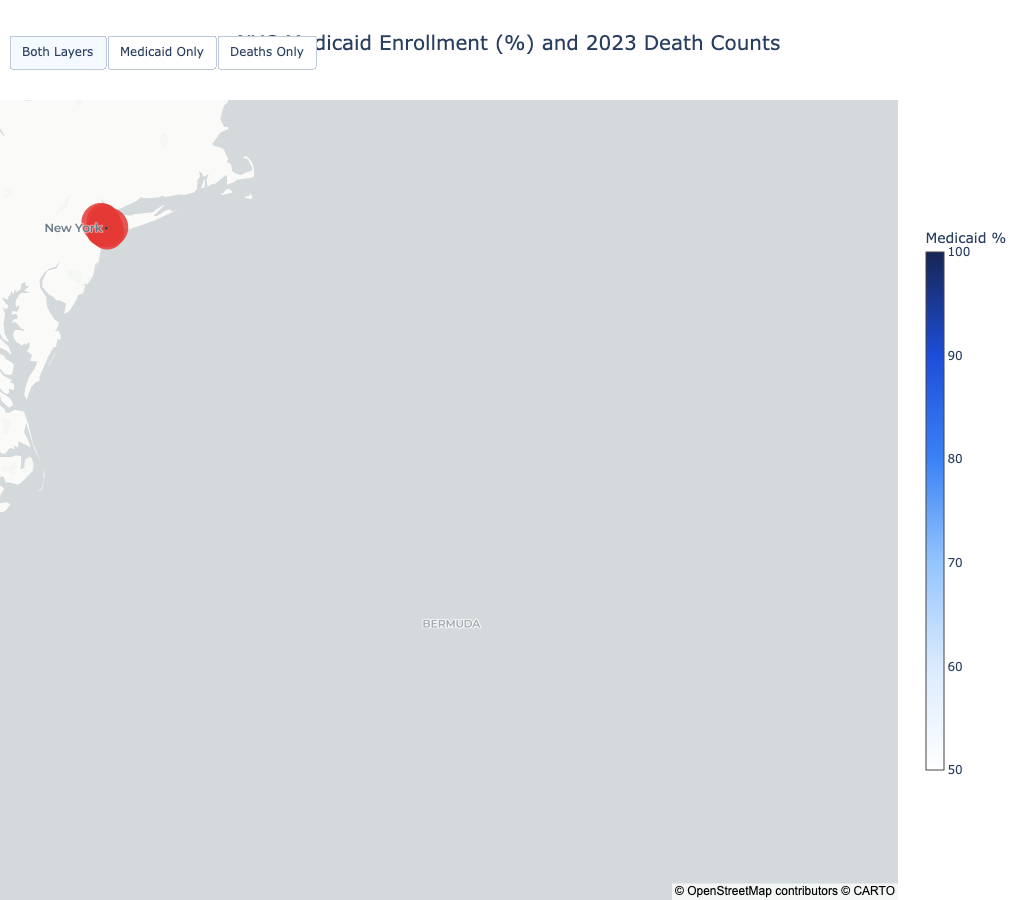

Interactive map saved successfully.


,commntydst,Total_Deaths,lat,lon
53,412,1425.0,40.69158,-73.77844
6,107,1399.0,40.78717,-73.97613
28,305,1300.0,40.66848,-73.87971
55,414,1073.0,40.58913,-73.81028
40,317,1007.0,40.64804,-73.93382
15,204,961.0,40.83381,-73.92080
37,314,891.0,40.63185,-73.95912
26,303,844.0,40.68769,-73.94056
12,201,733.0,40.81091,-73.91647


In [21]:

import pandas as pd
import numpy as np
import json
import plotly.graph_objects as go

# ==========================================
# 1. LOAD DATA
# ==========================================

insurance = pd.read_csv(
    "NYC_Program_Enrollment_by_ZIP.csv",
    dtype={"Zip_Code": str}
)

deaths = pd.read_csv(
    "CommunityDistrictSingleYearCounts2023.csv",
    low_memory=False
)

with open(
    "nyc-zip-code-tabulation-areas-polygons.geojson",
    "r"
) as f:
    zip_geojson = json.load(f)

with open("nyc_districts.geojson", "r") as f:
    cd_geojson = json.load(f)

insurance.columns = insurance.columns.str.strip()
deaths.columns = deaths.columns.str.strip()

# ==========================================
# 2. PREPARE INSURANCE DATA
# ==========================================

insurance["Zip_Code"] = (
    insurance["Zip_Code"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

programs = [
    "Medicaid",
    "CHP",
    "QHP APTC w/o CSR",
    "QHP Full Pay",
    "Essential Plan"
]

count_cols = [f"{p} Count" for p in programs]

for col in count_cols:
    if col not in insurance.columns:
        raise ValueError(f"Missing insurance column: {col}")

# Convert all counts together
insurance[count_cols] = (
    insurance[count_cols]
    .replace(",", "", regex=True)
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0)
)

# One row per ZIP code
insurance = (
    insurance.groupby(
        "Zip_Code",
        as_index=False
    )[count_cols].sum()
)

insurance["Total_Enrollments"] = (
    insurance[count_cols].sum(axis=1)
)

for program in programs:
    insurance[f"{program} Percentage"] = (
        insurance[f"{program} Count"]
        / insurance["Total_Enrollments"].replace(0, np.nan)
        * 100
    )

# ==========================================
# 3. PREPARE ZIP CODE GEOJSON
# ==========================================

for feature in zip_geojson["features"]:

    feature["properties"]["Zip_Code"] = (
        str(feature["properties"]["postalCode"])
        .strip()
        .zfill(5)
    )

valid_zips = {
    feature["properties"]["Zip_Code"]
    for feature in zip_geojson["features"]
}

insurance_map = insurance[
    insurance["Zip_Code"].isin(valid_zips)
    & (insurance["Total_Enrollments"] > 0)
].copy()

# ==========================================
# 4. PREPARE MORTALITY DATA
# ==========================================

deaths["commntydst"] = pd.to_numeric(
    deaths["commntydst"],
    errors="coerce"
)

# Use Total_Deaths if already available.
# Otherwise calculate it from broad,
# mutually exclusive cause categories.
#
# Do not sum age, sex, race, or specific
# cancer-site columns because those would
# double-count deaths.

if "Total_Deaths" in deaths.columns:

    total_deaths = pd.to_numeric(
        deaths["Total_Deaths"].astype(str).str.replace(
            ",", "", regex=False
        ),
        errors="coerce"
    )

else:

    causes = [
        "Deaths due to septicemia",
        "Deaths due to HIV",
        "Deaths due to malignant neoplasms(cancer)",
        "Deaths due to diabetes mellitus",
        "Deaths due to use of or poisoning by psychoactive substance excluding alcohol and tobacco",
        "Deaths due to Alzheimer's disease",
        "Deaths due to diseases of the heart",
        "Deaths due to essential hypertension and hypertensive renal disease",
        "Deaths due to cerebrovascular diseases",
        "Deaths due to influenza and pneumonia",
        "Deaths due to chronic lower respiratory diseases",
        "Deaths due to chronic liver disease and cirrhosis",
        "Deaths due to Nephritis_ Nephrotic Syndrome and Nephrosis",
        "Deaths due to Covid19",
        "Deaths due to accidents except for durg poisoning",
        "Deaths due to intentional self-harm(suicide)",
        "Deaths due to assault(homicide)",
        "Other causes"
    ]

    missing = [
        col for col in causes
        if col not in deaths.columns
    ]

    if missing:
        raise ValueError(
            f"Missing mortality columns: {missing}"
        )

    # Convert all cause columns together,
    # avoiding DataFrame fragmentation.
    numeric_causes = (
        deaths[causes]
        .replace(",", "", regex=True)
        .apply(pd.to_numeric, errors="coerce")
    )

    total_deaths = numeric_causes.sum(
        axis=1,
        min_count=len(causes)
    )

# Create a small mortality DataFrame
# without modifying the large original CSV
mortality = pd.DataFrame({
    "commntydst": deaths["commntydst"],
    "Total_Deaths": total_deaths
})

# Aggregate by community district
death_totals = (
    mortality.dropna(subset=["commntydst"])
    .groupby("commntydst", as_index=False)
    ["Total_Deaths"]
    .sum(min_count=1)
)

death_totals["commntydst"] = (
    death_totals["commntydst"].astype(int)
)

# ==========================================
# 5. GET COMMUNITY DISTRICT COORDINATES
#    DIRECTLY FROM GEOJSON
# ==========================================

# Your nyc_districts.geojson already has:
# commntydst, lon, lat
#
# No centroid calculations needed.

district_centers = pd.DataFrame([
    {
        "commntydst": feature["properties"]["commntydst"],
        "lon": feature["properties"]["lon"],
        "lat": feature["properties"]["lat"]
    }
    for feature in cd_geojson["features"]
])

# Standardize data types
for col in ["commntydst", "lon", "lat"]:
    district_centers[col] = pd.to_numeric(
        district_centers[col],
        errors="coerce"
    )

district_centers = district_centers.dropna(
    subset=["commntydst", "lon", "lat"]
)

district_centers["commntydst"] = (
    district_centers["commntydst"].astype(int)
)

# Ensure one coordinate per district
district_centers = district_centers.drop_duplicates(
    subset=["commntydst"]
)

# Merge mortality data with coordinates
death_map = death_totals.merge(
    district_centers,
    on="commntydst",
    how="inner",
    validate="one_to_one"
)

death_map = death_map.dropna(
    subset=["Total_Deaths", "lat", "lon"]
)

# ==========================================
# 6. CHECK MATCHING DISTRICTS
# ==========================================

print(
    "ZIP codes mapped:",
    insurance_map["Zip_Code"].nunique()
)

print(
    "Community districts with coordinates:",
    district_centers["commntydst"].nunique()
)

print(
    "Community districts matched to deaths:",
    death_map["commntydst"].nunique()
)

unmatched = set(
    death_totals["commntydst"]
) - set(
    death_map["commntydst"]
)

if unmatched:
    print(
        "Mortality districts without coordinates:",
        sorted(unmatched)
    )

# ==========================================
# 7. DEFINE MEDICAID COLOR SCALE
# ==========================================

# 50% = white
# 100% = darkest blue

medicaid_colors = [
    [0.00, "#FFFFFF"],
    [0.20, "#DBEAFE"],
    [0.40, "#93C5FD"],
    [0.60, "#3B82F6"],
    [0.80, "#1D4ED8"],
    [1.00, "#172554"]
]

# ==========================================
# 8. CREATE PLOTLY FIGURE
# ==========================================

fig = go.Figure()

# ==========================================
# 9. LAYER 1: MEDICAID ENROLLMENT
# ==========================================

hover_cols = [
    "Zip_Code",
    "Total_Enrollments",
    "Medicaid Count",
    "Medicaid Percentage",
    "CHP Count",
    "CHP Percentage",
    "QHP APTC w/o CSR Count",
    "QHP APTC w/o CSR Percentage",
    "QHP Full Pay Count",
    "QHP Full Pay Percentage",
    "Essential Plan Count",
    "Essential Plan Percentage"
]

fig.add_trace(
    go.Choroplethmap(
        geojson=zip_geojson,

        locations=insurance_map["Zip_Code"],

        featureidkey="properties.Zip_Code",

        z=insurance_map["Medicaid Percentage"],

        colorscale=medicaid_colors,

        zmin=50,
        zmax=100,

        marker=dict(
            opacity=0.45,
            line=dict(
                width=0.5,
                color="#64748B"
            )
        ),

        customdata=insurance_map[
            hover_cols
        ].to_numpy(),

        hovertemplate=(
            "<b>ZIP Code: %{customdata[0]}</b><br>"
            "<br>"
            "<b>Total Enrollments:</b> "
            "%{customdata[1]:,.0f}<br>"

            "<br><b>Medicaid</b><br>"
            "Count: %{customdata[2]:,.0f}<br>"
            "Percentage: %{customdata[3]:.2f}%<br>"

            "<br><b>CHP</b><br>"
            "Count: %{customdata[4]:,.0f}<br>"
            "Percentage: %{customdata[5]:.2f}%<br>"

            "<br><b>QHP APTC w/o CSR</b><br>"
            "Count: %{customdata[6]:,.0f}<br>"
            "Percentage: %{customdata[7]:.2f}%<br>"

            "<br><b>QHP Full Pay</b><br>"
            "Count: %{customdata[8]:,.0f}<br>"
            "Percentage: %{customdata[9]:.2f}%<br>"

            "<br><b>Essential Plan</b><br>"
            "Count: %{customdata[10]:,.0f}<br>"
            "Percentage: %{customdata[11]:.2f}%"

            "<extra></extra>"
        ),

        colorbar=dict(
            title="Medicaid %",
            ticksuffix="%",
            tickvals=[50, 60, 70, 80, 90, 100],
            len=0.7,
            thickness=18
        ),

        name="Medicaid Enrollment",
        showscale=True,
        visible=True
    )
)

# ==========================================
# 10. LAYER 2: DEATH COUNT BUBBLES
# ==========================================

# Larger bubbles indicate more deaths.
# Size is scaled by area rather than diameter.

max_deaths = death_map["Total_Deaths"].max()

sizeref = (
    2 * max_deaths / (40 ** 2)
    if max_deaths > 0 else 1
)

fig.add_trace(
    go.Scattermap(
        lat=death_map["lat"],
        lon=death_map["lon"],

        mode="markers",

        marker=dict(
            size=death_map["Total_Deaths"].clip(lower=0),

            sizemode="area",
            sizeref=sizeref,
            sizemin=5,

            color="#E53935",
            opacity=0.85
        ),

        customdata=death_map[
            ["commntydst", "Total_Deaths"]
        ].to_numpy(),

        hovertemplate=(
            "<b>Community District: "
            "%{customdata[0]}</b><br>"
            "<b>Total Deaths (2023):</b> "
            "%{customdata[1]:,.0f}"
            "<extra></extra>"
        ),

        name="2023 Death Counts",
        visible=True
    )
)

# ==========================================
# 11. MAP LAYOUT
# ==========================================

fig.update_layout(
    map=dict(
        style="carto-positron",

        center=dict(
            lat=40.7128,
            lon=-73.94
        ),

        zoom=9.6
    ),

    title=dict(
        text=(
            "NYC Medicaid Enrollment (%) "
            "and 2023 Death Counts"
        ),
        x=0.5,
        font=dict(size=20)
    ),

    height=900,

    margin=dict(
        l=0,
        r=90,
        t=100,
        b=0
    ),

    legend=dict(
        title="Map Layers",
        x=0.01,
        y=0.99,
        bgcolor="rgba(255,255,255,0.85)"
    )
)

# ==========================================
# 12. LAYER TOGGLE BUTTONS
# ==========================================

fig.update_layout(
    updatemenus=[
        dict(
            type="buttons",
            direction="right",

            buttons=[
                dict(
                    label="Both Layers",
                    method="update",
                    args=[
                        {"visible": [True, True]}
                    ]
                ),

                dict(
                    label="Medicaid Only",
                    method="update",
                    args=[
                        {"visible": [True, False]}
                    ]
                ),

                dict(
                    label="Deaths Only",
                    method="update",
                    args=[
                        {"visible": [False, True]}
                    ]
                )
            ],

            x=0.01,
            y=1.04,
            xanchor="left",
            yanchor="bottom",
            showactive=True
        )
    ]
)

# ==========================================
# 13. DISPLAY MAP
# ==========================================

fig.show()

# ==========================================
# 14. SAVE INTERACTIVE HTML MAP
# ==========================================

fig.write_html(
    "NYC_Medicaid_Deaths_Layered_Map.html"
)

print("Interactive map saved successfully.")

# ==========================================
# 15. REVIEW MORTALITY RESULTS
# ==========================================

display(
    death_map[
        [
            "commntydst",
            "Total_Deaths",
            "lat",
            "lon"
        ]
    ].sort_values(
        "Total_Deaths",
        ascending=False
    ).head(15)
)
